# KAVACH: deep-learning router (Kaggle, GPU T4 x2, about 45 min)

**Before running**
1. Upload **`kavach_kaggle.zip`** as a new Kaggle **Dataset** (name it `kavach`). Kaggle unzips it automatically.
2. In this notebook: **Add Input → Your datasets → kavach**.
3. **Settings:** Accelerator **GPU T4 x2**, Internet **On** (needed to download the pretrained models from Hugging Face).
4. **Save Version → Save & Run All**, or run the cells one by one.
5. When it finishes, download **`kavach_dl_outputs.zip`** from the Output panel and unzip it into your `kavach` folder.

**What it does**
- Fine-tunes three multilingual transformers as KAVACH's *router*: XLM-R base, MuRIL base and DistilmBERT. XLM-R and MuRIL use 3 seeds each.
- Trains a TF-IDF + logistic-regression baseline.
- Tests generalisation: routers are trained *without* the India-safety data, then tested on it.
- Re-runs the end-to-end Gemini cascade with each learned router. It uses your cached Gemini answers, so it needs **0 API calls** and no key.


In [1]:
# 1. SETUP -------------------------------------------------------------------
import glob, json, os, shutil, subprocess, sys, time
src = glob.glob('/kaggle/input/**/kavach/router.py', recursive=True)
assert src, 'Add the kavach dataset to this notebook (Add Input -> Your datasets)'
root = os.path.dirname(os.path.dirname(src[0]))
W = '/kaggle/working/kavach'
shutil.copytree(root, W, dirs_exist_ok=True)
os.chdir(W); sys.path.insert(0, W)
for d in ['dl/runs', 'dl/logs', 'dl/report']:
    os.makedirs(d, exist_ok=True)
print('project at', W)
print(subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv'], capture_output=True, text=True).stdout)
import torch, transformers, sklearn
print('torch', torch.__version__, '| transformers', transformers.__version__, '| GPUs', torch.cuda.device_count())
print('cache present:', os.path.exists('bench/results/llm_cache.sqlite'), '| judge results present:', os.path.exists('bench/results/test_llm.json'))


project at /kaggle/working/kavach
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB

torch 2.11.0+cu128 | transformers 5.16.1 | GPUs 2
cache present: True | judge results present: True


## 2. Classical baseline: TF-IDF + logistic regression (CPU, about 1 min)

In [2]:
!python dl/tfidf_baseline.py --out dl/runs/tfidf | tail -1
!python dl/tfidf_baseline.py --exclude_source india-safety --out dl/runs/tfidf_loso | tail -1


FINAL {"base_model": "tfidf-char-lr", "threshold": 0.3202429067520081, "target_recall": 0.95, "exclude_source": null, "best_val_auroc": 0.9663086489542114, "kind": "sklearn", "test_auroc": 0.9537673649260713, "test_auprc": 0.9605244656000422, "n_params_M": 0.3}
FINAL {"base_model": "tfidf-char-lr", "threshold": 0.3392678682180036, "target_recall": 0.95, "exclude_source": "india-safety", "best_val_auroc": 0.9502801120448179, "kind": "sklearn", "test_auroc": 0.7940590929025283, "test_auprc": 0.8282138340717597, "n_params_M": 0.3}


## 3. Fine-tune the transformers on both GPUs (about 30 min)

In [3]:
MODELS = {'xlmr': 'xlm-roberta-base', 'muril': 'google/muril-base-cased', 'mbert': 'distilbert-base-multilingual-cased'}
jobs = []
for tag, seeds in [('xlmr', [13, 21, 42]), ('muril', [13, 21, 42]), ('mbert', [13])]:
    for s in seeds:
        jobs.append((f'{tag}_s{s}', MODELS[tag], s, None))
for tag in ['xlmr', 'muril']:                                    # generalisation to an unseen source
    jobs.append((f'{tag}_loso', MODELS[tag], 13, 'india-safety'))
jobs = [j for j in jobs if not os.path.exists(f'dl/runs/{j[0]}/router_config.json')]
ngpu = max(torch.cuda.device_count(), 1)
queues = [jobs[i::ngpu] for i in range(ngpu)]
procs = []
for g, q in enumerate(queues):
    if not q: continue
    cmd = ' ; '.join(
        f'python dl/train_router.py --model {m} --seed {s} --epochs 4 --bs 16 --lr 2e-5 --max_len 256 '
        + (f'--exclude_source {ex} ' if ex else '') + f'--out dl/runs/{name} > dl/logs/{name}.log 2>&1'
        for name, m, s, ex in q)
    procs.append(subprocess.Popen(cmd, shell=True, env={**os.environ, 'CUDA_VISIBLE_DEVICES': str(g), 'TOKENIZERS_PARALLELISM': 'false'}))
    print(f'GPU {g}:', [j[0] for j in q])
while any(p.poll() is None for p in procs):
    time.sleep(60)
    done = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob('dl/runs/*/router_config.json'))
    print(time.strftime('%H:%M'), 'finished:', done, flush=True)
for f in sorted(glob.glob('dl/logs/*.log')):
    lines = open(f).read().strip().splitlines()
    print('=====', f); print('\n'.join(l for l in lines if l.startswith('{') or l.startswith('FINAL') or 'Error' in l)[-1500:])


GPU 0: ['xlmr_s13', 'xlmr_s42', 'muril_s21', 'mbert_s13', 'muril_loso']
GPU 1: ['xlmr_s21', 'muril_s13', 'muril_s42', 'xlmr_loso']
11:38 finished: ['tfidf', 'tfidf_loso']
11:39 finished: ['tfidf', 'tfidf_loso']
11:40 finished: ['tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21']
11:41 finished: ['tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21']
11:42 finished: ['tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21']
11:43 finished: ['muril_s13', 'tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21', 'xlmr_s42']
11:44 finished: ['muril_s13', 'tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21', 'xlmr_s42']
11:45 finished: ['muril_s13', 'muril_s21', 'tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21', 'xlmr_s42']
11:46 finished: ['muril_s13', 'muril_s21', 'muril_s42', 'tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21', 'xlmr_s42']
11:47 finished: ['mbert_s13', 'muril_s13', 'muril_s21', 'muril_s42', 'tfidf', 'tfidf_loso', 'xlmr_s13', 'xlmr_s21', 'xlmr_s42']
11:48 finished: ['mbert_s13', 'muril_s13', 'muril_s21', 'muril_s42', 'tfid

## 4. Analysis: routing recall and cost, ROC, languages, unseen source

rules router: Route+ 71.8  Route- 38.2
DistilmBERT                        AUROC  95.9 | learned R+  96.1 R-  26.5 | matched-budget R+  97.8 | union R+  98.0 R-  54.5
MuRIL base (w/o india-safety)      AUROC  82.8 | learned R+  74.0 R-  14.1 | matched-budget R+  80.6 | union R+  87.3 R-  45.4 | held-out {'source': 'india-safety', 'recall_learned': 47.6, 'recall_rules': 66.1, 'auroc': np.float64(67.3)}
MuRIL base                         AUROC  95.6 | learned R+  94.9 R-  18.8 | matched-budget R+  97.7 | union R+  97.4 R-  48.2
MuRIL base                         AUROC  95.2 | learned R+  96.0 R-  31.3 | matched-budget R+  97.0 | union R+  98.0 R-  57.1
MuRIL base                         AUROC  95.8 | learned R+  95.4 R-  18.1 | matched-budget R+  97.9 | union R+  97.7 R-  48.1
TF-IDF + LR                        AUROC  95.4 | learned R+  95.7 R-  29.1 | matched-budget R+  97.1 | union R+  98.1 R-  54.8
TF-IDF + LR (w/o india-safety)     AUROC  79.4 | learned R+  63.1 R-  22.8 | matched-bud

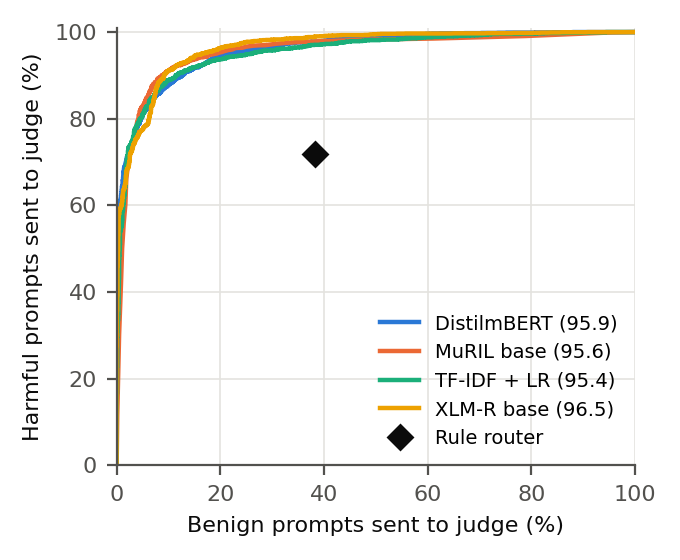

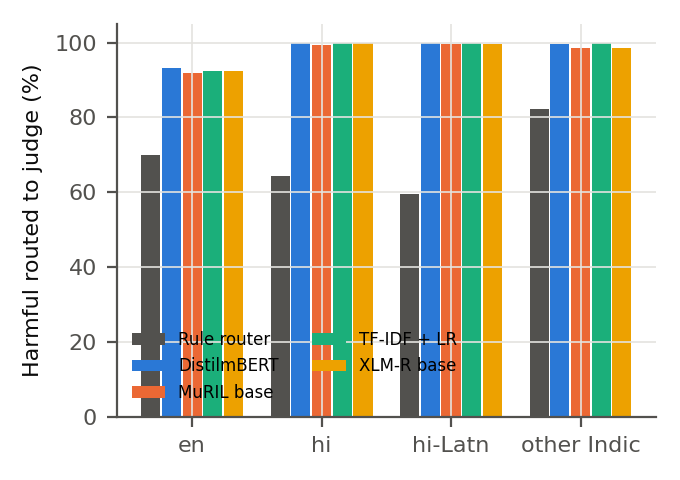

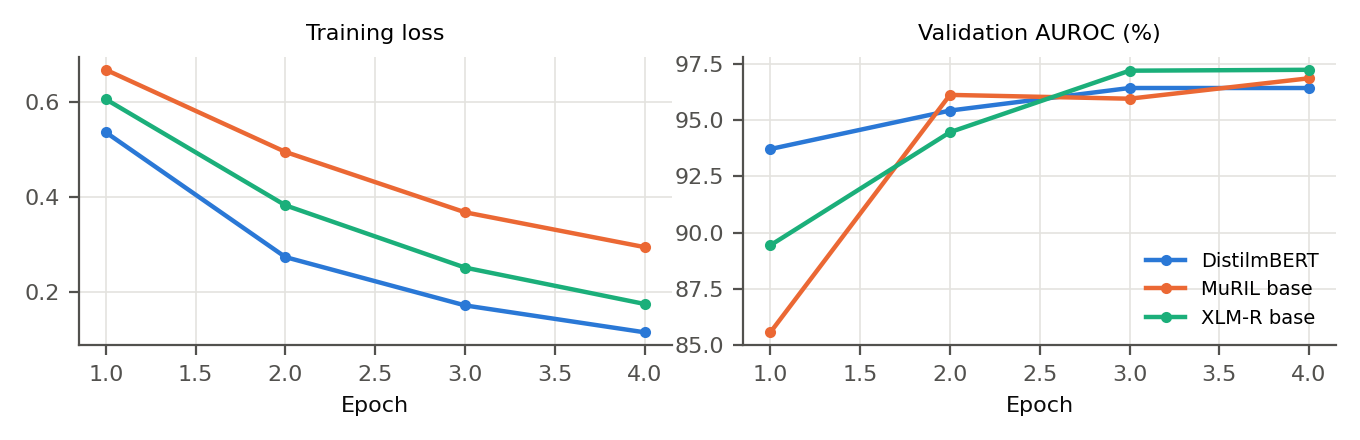

In [4]:
!python dl/analyze.py --runs dl/runs --out dl/report
from IPython.display import Image, display
for f in ['fig_router_roc.png', 'fig_router_lang.png', 'fig_training.png']:
    if os.path.exists(f'dl/report/{f}'):
        display(Image(f'dl/report/{f}', width=650))


## 5. End-to-end cascade with the learned routers (served from the Gemini cache: 0 API calls)

In [5]:
# Optional: a key is only needed if something is missing from the cache (Add-ons -> Secrets -> GEMINI_API_KEY)
try:
    from kaggle_secrets import UserSecretsClient
    os.environ['GEMINI_API_KEY'] = UserSecretsClient().get_secret('GEMINI_API_KEY')
    print('using GEMINI_API_KEY secret for any cache misses')
except Exception:
    print('no secret set: cache-only mode')

# pick the best transformer seed per model family BY VALIDATION AUROC (no test data used for selection)
best = {}
for d in glob.glob('dl/runs/*_s*'):
    cfg = json.load(open(f'{d}/router_config.json'))
    fam = os.path.basename(d).split('_')[0]
    if fam not in best or cfg['best_val_auroc'] > best[fam][1]:
        best[fam] = (d, cfg['best_val_auroc'])
print({k: (os.path.basename(v[0]), round(v[1], 4)) for k, v in best.items()})
!python dl/cascade_eval.py --router dl/runs/tfidf --label tfidf 2>&1 | grep -E "^(group|all|judge-call|new API)"
for fam, (d, _) in best.items():
    print('=' * 20, fam)
    !python dl/cascade_eval.py --router {d} --label {fam} 2>&1 | grep -E "^(group|all|judge-call|new API)"


no secret set: cache-only mode
{'xlmr': ('xlmr_s42', 0.9768), 'muril': ('muril_s42', 0.9722), 'mbert': ('mbert_s13', 0.9642)}
group                         cascade-learned-tf  cascade-union-tfid
all DSR                             79.5 (n=117 )        81.2 (n=117 )
all FRR                              0.0 (n=69  )         0.0 (n=69  )
all ROUTE+                          99.1 (n=117 )        99.1 (n=117 )
all ROUTE-                          33.3 (n=69  )        68.1 (n=69  )
judge-call rate %                           74.2                87.1
new API calls: 12 (0 means everything came from the cache)
==================== xlmr
group                         cascade-learned-xl  cascade-union-xlmr
all DSR                             74.4 (n=117 )        78.6 (n=117 )
all FRR                              0.0 (n=69  )         0.0 (n=69  )
all ROUTE+                          96.6 (n=117 )        97.4 (n=117 )
all ROUTE-                          11.6 (n=69  )        58.0 (n=69  )
judge-call rat

## 6. Paper tables + package outputs

In [6]:
!python bench/make_tables.py
overall = max(best.items(), key=lambda kv: kv[1][1])          # best family by validation AUROC -> demo router
print('demo router:', overall[0], os.path.basename(overall[1][0]))
B = '/kaggle/working/bundle'
shutil.rmtree(B, ignore_errors=True)
for sub in ['dl/report', 'paper/tables']:
    shutil.copytree(sub, f'{B}/{sub}')
for d in glob.glob('dl/runs/*'):                                # metrics only, no weights (they are large)
    os.makedirs(f'{B}/{d}', exist_ok=True)
    for f in ['router_config.json', 'history.json', 'test_preds.jsonl', 'val_preds.jsonl']:
        if os.path.exists(f'{d}/{f}'):
            shutil.copy(f'{d}/{f}', f'{B}/{d}/')
shutil.copy('dl/runs/tfidf/model.joblib', f'{B}/dl/runs/tfidf/')    # small classical router, usable in the demo
shutil.copytree(overall[1][0], f'{B}/dl/best_router')              # the transformer router used in the demo
os.makedirs(f'{B}/bench/results', exist_ok=True)
for f in glob.glob('bench/results/test_llm_router_*.json'):
    shutil.copy(f, f'{B}/bench/results/')
shutil.copytree('dl/logs', f'{B}/dl/logs')
zp = shutil.make_archive('/kaggle/working/kavach_dl_outputs', 'zip', B)
shutil.rmtree(B)
print(f'Created {zp} ({os.path.getsize(zp)/1e6:.0f} MB)')
from IPython.display import FileLink; display(FileLink('kavach_dl_outputs.zip'))


tables -> /kaggle/working/kavach/paper/tables ['ablation.tex', 'llm.tex', 'offline.tex']
demo router: xlmr xlmr_s42
Created /kaggle/working/kavach_dl_outputs.zip (514 MB)


/kaggle/working/kavach/kavach_dl_outputs.zip